# LIDC-IDRI: Exploração e Análise de Nódulos Pulmonares

Abordagem usando `pylidc` para carregar e processar dados de CT scans com anotações de múltiplos radiólogos.

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">

  <h1 style="color: #c25719; border-bottom: 2px solid #c25719; padding-bottom: 8px; margin-top: 0;">
    LIDC-IDRI — Lung Image Database Consortium
  </h1>

  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
    The reference dataset for lung nodule detection
  </h3>

  <p>
    O LIDC-IDRI é o dataset mais citado em deteção e classificação de nódulos pulmonares. Foi criado por 7 instituições académicas americanas, em colaboração com a <em>Foundation for the National Institutes of Health</em> e a <em>National Cancer Institute</em>, e é público desde 2011 (Armato III et al., 2011).
  </p>

  <p>
    Ao contrário do LNDb- que é de uma única instituição (CHUSJ, Porto) e usa uma metodologia <em>single-blind</em>- o LIDC-IDRI foi anotado por <strong>4 radiotorácicos experientes</strong> em duas fases: uma primeira leitura cega (<em>blinded-read</em>) e uma segunda fase não-cega (<em>unblinded-read</em>), em que cada radiologista teve acesso às marcações anonimizadas dos outros três.
  </p>

  <p>
    Este notebook faz uma análise exploratória inicial do LIDC-IDRI, com o objetivo de extrair uma tabela de nódulos e de identificar as diferenças estruturais face ao LNDb.
  </p>

</div>

## Setup

Importamos as bibliotecas habituais e o `pylidc`, que lê os XMLs oficiais do LIDC e constrói uma base de dados SQLite local. Isto é essencial porque os XMLs originais são difíceis de consultar diretamente.

In [9]:
import pylidc as pl
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
from pathlib import Path

# Configuração do pylidc (ver .pylidcrc)
# O pylidc lê o ficheiro ~/.pylidcrc, que tem de apontar para a pasta dos XMLs
#print("Pylidc config:", pl.config)

# Quantos scans/pacientes temos disponíveis?
n_scans = pl.query(pl.Scan).count()
n_patients = pl.query(pl.Scan.patient_id).distinct().count()
n_annotations = pl.query(pl.Annotation).count()

print(f"Scans (séries de TC): {n_scans}")
print(f"Pacientes únicos:     {n_patients}")
print(f"Anotações totais:     {n_annotations}")

Scans (séries de TC): 1018
Pacientes únicos:     1010
Anotações totais:     6859


## 1. Ler um scan com `pylidc`

Antes de escalar para o dataset inteiro, confirmamos que a biblioteca funciona no nosso ambiente. Escolhemos o `LIDC-IDRI-0001` porque é pequeno e está sempre presente.

In [21]:
patient_id = 'LIDC-IDRI-0001'
scan = pl.query(pl.Scan).filter(pl.Scan.patient_id == patient_id).first()

if scan is None:
    print(f"Scan  não encontrado")
else:
    print(f"  patient_id:  {scan.patient_id}")
    print(f"  study_uid:   {scan.study_instance_uid[:40]}...")
    print(f"  series_uid:  {scan.series_instance_uid[:40]}...")
    print(f"  slice_thickness: {scan.slice_thickness} mm")
    print(f"  pixel_spacing:   {scan.pixel_spacing} mm")
    print(f"  n annotations:   {len(scan.annotations)}")

  patient_id:  LIDC-IDRI-0001
  study_uid:   1.3.6.1.4.1.14519.5.2.1.6279.6001.298806...
  series_uid:  1.3.6.1.4.1.14519.5.2.1.6279.6001.179049...
  slice_thickness: 2.5 mm
  pixel_spacing:   0.703125 mm
  n annotations:   4


## 2. Explorar Anotações

**Cada objeto `Annotation` representa a leitura de um radiologista sobre um nódulo.** Como cada nódulo foi anotado por até 4 radiologistas, temos de agrupar as anotações que se referem ao **mesmo nódulo físico**.

O `pylidc` faz isto por nós através de `scan.cluster_annotations()`, que devolve uma lista de listas: cada sublista contém as anotações (1 a 4) que correspondem ao mesmo nódulo.

In [23]:
clusters = scan.cluster_annotations()

print(f"Nódulos únicos: {len(clusters)}")
print(f"Anotações totais: {len(scan.annotations)}")
print()

for i, cluster in enumerate(clusters):
    print(f"  Nódulo {i}: {len(cluster)} anotações")
    for ann in cluster:
        mal = ann.malignancy
        diam = ann.diameter
        print(f"    - id={ann.id}  malignidade={mal}  diâmetro={diam:.1f} mm")

Nódulos únicos: 1
Anotações totais: 4

  Nódulo 0: 4 anotações
    - id=84  malignidade=5  diâmetro=32.2 mm
    - id=85  malignidade=5  diâmetro=33.2 mm
    - id=86  malignidade=5  diâmetro=32.0 mm
    - id=87  malignidade=4  diâmetro=33.7 mm


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">

  <h3 style="color: #c25719; border-bottom: 2px solid #c25719; padding-bottom: 8px;">
    As 9 características subjetivas (por radiologista)
  </h3>

  <p>
    Para cada nódulo ≥ 3 mm, cada um dos 4 radiotorácicos avaliou
    subjetivamente as seguintes características. São <strong>avaliações
    individuais</strong> — ou seja, o mesmo nódulo tem 4 conjuntos de
    valores (um por radiologista).
  </p>

  <table style="width: 100%; border-collapse: collapse; margin-top: 15px; color: #f0f0f0;">
    <thead>
      <tr style="background-color: #c25719; color: #ffffff;">
        <th style="padding: 8px; border: 1px solid #444; text-align: left;">Característica</th>
        <th style="padding: 8px; border: 1px solid #444; text-align: left;">Escala</th>
        <th style="padding: 8px; border: 1px solid #444; text-align: left;">Significado</th>
      </tr>
    </thead>
    <tbody>
      <tr>
        <td style="padding: 8px; border: 1px solid #444;"><code>malignancy</code></td>
        <td style="padding: 8px; border: 1px solid #444;">1–5</td>
        <td style="padding: 8px; border: 1px solid #444;">Probabilidade global de cancro</td>
      </tr>
      <tr style="background-color: #00183a40;">
        <td style="padding: 8px; border: 1px solid #444;"><code>subtlety</code></td>
        <td style="padding: 8px; border: 1px solid #444;">1–5</td>
        <td style="padding: 8px; border: 1px solid #444;">Dificuldade em detetar o nódulo</td>
      </tr>
      <tr>
        <td style="padding: 8px; border: 1px solid #444;"><code>internalStructure</code></td>
        <td style="padding: 8px; border: 1px solid #444;">1–4</td>
        <td style="padding: 8px; border: 1px solid #444;">Sólido / subsólido / parte-sólido / cavitário</td>
      </tr>
      <tr style="background-color: #00183a40;">
        <td style="padding: 8px; border: 1px solid #444;"><code>calcification</code></td>
        <td style="padding: 8px; border: 1px solid #444;">1–6</td>
        <td style="padding: 8px; border: 1px solid #444;">Padrão de calcificação (1 = popcorn benigno, 6 = sem calcificação)</td>
      </tr>
      <tr>
        <td style="padding: 8px; border: 1px solid #444;"><code>sphericity</code></td>
        <td style="padding: 8px; border: 1px solid #444;">1–5</td>
        <td style="padding: 8px; border: 1px solid #444;">Semelhança com esfera</td>
      </tr>
      <tr style="background-color: #00183a40;">
        <td style="padding: 8px; border: 1px solid #444;"><code>margin</code></td>
        <td style="padding: 8px; border: 1px solid #444;">1–5</td>
        <td style="padding: 8px; border: 1px solid #444;">Nitidez da margem</td>
      </tr>
      <tr>
        <td style="padding: 8px; border: 1px solid #444;"><code>lobulation</code></td>
        <td style="padding: 8px; border: 1px solid #444;">1–5</td>
        <td style="padding: 8px; border: 1px solid #444;">Contorno ondulado (lobulado)</td>
      </tr>
      <tr style="background-color: #00183a40;">
        <td style="padding: 8px; border: 1px solid #444;"><code>spiculation</code></td>
        <td style="padding: 8px; border: 1px solid #444;">1–5</td>
        <td style="padding: 8px; border: 1px solid #444;">Espículas radiantes (sunburst sign)</td>
      </tr>
      <tr>
        <td style="padding: 8px; border: 1px solid #444;"><code>texture</code></td>
        <td style="padding: 8px; border: 1px solid #444;">1–5</td>
        <td style="padding: 8px; border: 1px solid #444;">Textura (1 = GGO, 5 = sólido)</td>
      </tr>
    </tbody>
  </table>

  <h3 style="color: #c25719; border-bottom: 2px solid #c25719; padding-bottom: 8px; margin-top: 25px;">
    Métricas geométricas (calculadas pelo pylidc)
  </h3>

  <table style="width: 100%; border-collapse: collapse; color: #f0f0f0;">
    <thead>
      <tr style="background-color: #c25719; color: #ffffff;">
        <th style="padding: 8px; border: 1px solid #444; text-align: left;">Atributo</th>
        <th style="padding: 8px; border: 1px solid #444; text-align: left;">Unidade</th>
        <th style="padding: 8px; border: 1px solid #444; text-align: left;">Significado</th>
      </tr>
    </thead>
    <tbody>
      <tr>
        <td style="padding: 8px; border: 1px solid #444;"><code>diameter</code></td>
        <td style="padding: 8px; border: 1px solid #444;">mm</td>
        <td style="padding: 8px; border: 1px solid #444;">Diâmetro maior do nódulo</td>
      </tr>
      <tr style="background-color: #00183a40;">
        <td style="padding: 8px; border: 1px solid #444;"><code>centroid</code></td>
        <td style="padding: 8px; border: 1px solid #444;">(x, y, z) em píxeis</td>
        <td style="padding: 8px; border: 1px solid #444;">Centroide do nódulo no volume</td>
      </tr>
      <tr>
        <td style="padding: 8px; border: 1px solid #444;"><code>volume</code></td>
        <td style="padding: 8px; border: 1px solid #444;">mm³</td>
        <td style="padding: 8px; border: 1px solid #444;">Volume do nódulo (via <code>pylidc.utils.volume</code>)</td>
      </tr>
    </tbody>
  </table>

  <p style="margin-top: 20px; font-size: 0.9em; color: #cccccc;">
    <strong>Nota:</strong> os valores subjetivos são avaliações
    <strong>individuais por radiologista</strong>, não valores de consenso.
    Um nódulo com 4 anotações tem 4 linhas de características- cabe ao
    pipeline decidir como as agregar.
  </p>

</div>

In [30]:
# Seleção de 5 nódulos de scans diferentes, para mostrar
# como as características variam na prática.
exemplos = []
scans_alvo = ['LIDC-IDRI-0001', 'LIDC-IDRI-0003',
              'LIDC-IDRI-0004', 'LIDC-IDRI-0005', 'LIDC-IDRI-0008']

for pid in scans_alvo:
    s = pl.query(pl.Scan).filter(pl.Scan.patient_id == pid).first()
    if s is None:
        continue

   
    clusters_s = s.cluster_annotations()

    ann = clusters_s[0][0]  # primeiro nódulo, primeiro radiologista

    exemplos.append({
        'scan_id':        pid,
        'diâmetro (mm)':  round(ann.diameter, 1),
        'malignancy':     ann.malignancy,
        'subtlety':       ann.subtlety,
        'internalStruct': ann.internalStructure,
        'calcification':  ann.calcification,
        'sphericity':     ann.sphericity,
        'margin':         ann.margin,
        'lobulation':     ann.lobulation,
        'spiculation':    ann.spiculation,
        'texture':        ann.texture,
    })

df_exemplos = pd.DataFrame(exemplos)
df_exemplos

,scan_id,diâmetro (mm),malignancy,subtlety,internalStruct,calcification,sphericity,margin,lobulation,spiculation,texture
0,LIDC-IDRI-0001,32.2,5,5,1,6,3,3,3,4,5
1,LIDC-IDRI-0003,31.7,2,1,1,6,5,2,1,1,1
2,LIDC-IDRI-0004,6.3,2,3,1,6,4,5,1,1,5
3,LIDC-IDRI-0005,6.3,3,3,1,6,4,5,1,1,5
4,LIDC-IDRI-0008,8.2,3,3,1,6,4,4,1,1,5


## 3. Cobertura de malignidade (quantos nódulos têm as 4 anotações?)

**Quantos nódulos têm o "label completo" (4 radiólogos) vs. quantos têm menos?**

Estratégia: para cada cluster de anotações, contar em quantos radiologistas o campo `malignancy` está preenchido (não é `NaN` nem `-1`).

In [12]:
from collections import Counter

cobertura = Counter()   # {n_rad_que_anotaram: nº de nódulos}
sem_malignidade = 0
total_nodulos = 0

for scan in pl.query(pl.Scan):
    clusters = scan.cluster_annotations()
    for cluster in clusters:
        total_nodulos += 1
        # conta quantas anotações têm malignidade válida (1-5)
        validos = sum(
            1 for a in cluster
            if a.malignancy is not None and 1 <= a.malignancy <= 5
        )
        cobertura[validos] += 1
        if validos == 0:
            sem_malignidade += 1

print(f"Total de nódulos: {total_nodulos}")
print(f"Nódulos sem malignidade: {sem_malignidade}")
print()
print("Distribuição de cobertura (nº de radiologistas com malignidade válida):")
for k in sorted(cobertura, reverse=True):
    pct = 100 * cobertura[k] / total_nodulos
    print(f"  {k} radiólogos: {cobertura[k]:5d} nódulos ({pct:5.1f}%)")

Failed to reduce all groups to <= 4 Annotations.
Some nodules may be close and must be grouped manually.
Failed to reduce all groups to <= 4 Annotations.
Some nodules may be close and must be grouped manually.
Failed to reduce all groups to <= 4 Annotations.
Some nodules may be close and must be grouped manually.
Failed to reduce all groups to <= 4 Annotations.
Some nodules may be close and must be grouped manually.
Failed to reduce all groups to <= 4 Annotations.
Some nodules may be close and must be grouped manually.
Failed to reduce all groups to <= 4 Annotations.
Some nodules may be close and must be grouped manually.
Failed to reduce all groups to <= 4 Annotations.
Some nodules may be close and must be grouped manually.
Failed to reduce all groups to <= 4 Annotations.
Some nodules may be close and must be grouped manually.
Failed to reduce all groups to <= 4 Annotations.
Some nodules may be close and must be grouped manually.
Failed to reduce all groups to <= 4 Annotations.
Some n

O pylidc tem um bug conhecido no clustering: nódulos espacialmente próximos são por vezes fundidos num só cluster, resultando em grupos com **5, 6, 7 ou 8 anotações** (quando o máximo real é 4 radiologistas). Ainda não foram removidos estes casos, mas estão assinalados na tabela abaixo na coluna `cluster_suspeito` do DataFrame.

**Ideia:** excluir os clusters suspeitos (< 1%), porque não têm interpretação válida como um único nódulo.

**Discustir com o grupo!!**

## 4. Processar Anotações

Extrair coordenadas e características de cada anotação para análise.

**Nota sobre o `radiologo_id`:** no LIDC, a identidade dos radiologistas não é rastreável entre scans. O que podemos fazer é numerar as anotações dentro de um cluster (1 a 4). Isto **não é equivalente** ao `RadID` do LNDb, que identifica consistentemente o mesmo radiologista em todos os scans.

In [ ]:
def extrair_nodulos_lidc(scan, max_nodulos=None):
    """NOTA: clusters com mais de 4 anotações sinalizamos com
    `cluster_suspeito=True` para poderem ser filtrados depois."""
    registos = []
    clusters = scan.cluster_annotations()

    for nodulo_idx, cluster in enumerate(clusters):
        if max_nodulos and nodulo_idx >= max_nodulos:
            break

        suspeito = len(cluster) > 4  # detetar cluster com mais de 4 anotações (bug do pylidc)

        for radiologista_idx, ann in enumerate(cluster):
            x, y, z = ann.centroid
            registos.append({
                'dataset':            'LIDC-IDRI',
                'scan_id':            scan.patient_id,
                'nodulo_id':          nodulo_idx,
                'x':                  float(x),
                'y':                  float(y),
                'z':                  float(z),
                'diametro_mm':        float(ann.diameter) if ann.diameter is not None else np.nan,
                'categoria':          1,
                'malignidade_rating': ann.malignancy,
                'radiologo_id':       radiologista_idx + 1,
                'cluster_suspeito':   suspeito,
            })
    return registos


todos = []
for pid in ['LIDC-IDRI-0001', 'LIDC-IDRI-0002', 'LIDC-IDRI-0003',
            'LIDC-IDRI-0004', 'LIDC-IDRI-0005']:
    s = pl.query(pl.Scan).filter(pl.Scan.patient_id == pid).first()
    if s is None:
        continue
    todos.extend(extrair_nodulos_lidc(s))

df_amostra = pd.DataFrame(todos)

# se decidirmos remover os clusters suspeitos (com mais de 4 anotações), descomentar a linha abaixo
#df_amostra = df_amostra[~df_amostra['cluster_suspeito']] 


"QUAL DESTAS FORMAS ESTÁ CORRETA????"
print(f"Amostra limpa: {len(df_amostra)} anotações "
      f"({df_amostra['nodulo_id'].nunique()} nódulos únicos em "
      f"{df_amostra['scan_id'].nunique()} scans)")

n_nodulos = df_amostra.groupby(['scan_id', 'nodulo_id']).ngroups
print(f"Amostra: {len(df_amostra)} anotações ({n_nodulos} nódulos únicos em "
      f"{df_amostra['scan_id'].nunique()} scans)")

# Ver distribuição de anotações por nódulo- confirmação de que a lógica está certa
print("\nAnotações por nódulo:")
print(df_amostra.groupby(['scan_id', 'nodulo_id']).size().reset_index(name='n_anotacoes'))

df_amostra.head(10)

Amostra limpa: 32 anotações (4 nódulos únicos em 5 scans)
Amostra: 32 anotações (10 nódulos únicos em 5 scans)

Anotações por nódulo:
          scan_id  nodulo_id  n_anotacoes
0  LIDC-IDRI-0001          0            4
1  LIDC-IDRI-0002          0            2
2  LIDC-IDRI-0003          0            1
3  LIDC-IDRI-0003          1            4
4  LIDC-IDRI-0003          2            4
5  LIDC-IDRI-0003          3            4
6  LIDC-IDRI-0004          0            4
7  LIDC-IDRI-0005          0            4
8  LIDC-IDRI-0005          1            4
9  LIDC-IDRI-0005          2            1


,dataset,scan_id,nodulo_id,x,y,z,diametro_mm,categoria,malignidade_rating,radiologo_id,cluster_suspeito
0,LIDC-IDRI,LIDC-IDRI-0001,0,365.874473,315.048523,89.551688,32.205888,1,5,1,False
1,LIDC-IDRI,LIDC-IDRI-0001,0,367.850606,316.277254,89.728129,33.188692,1,5,2,False
2,LIDC-IDRI,LIDC-IDRI-0001,0,366.955527,316.133418,89.538755,31.959332,1,5,3,False
3,LIDC-IDRI,LIDC-IDRI-0001,0,366.502720,316.467900,89.801959,33.669337,1,4,4,False
4,LIDC-IDRI,LIDC-IDRI-0002,0,363.265779,345.634122,184.442801,30.023172,1,5,1,False
5,LIDC-IDRI,LIDC-IDRI-0002,0,359.058796,344.810442,185.646284,31.540171,1,4,2,False
6,LIDC-IDRI,LIDC-IDRI-0003,0,346.394690,368.923894,66.148673,31.664468,1,2,1,False
7,LIDC-IDRI,LIDC-IDRI-0003,1,349.583636,366.900000,75.232727,30.351544,1,5,1,False
8,LIDC-IDRI,LIDC-IDRI-0003,1,350.834008,367.080972,75.275304,30.117853,1,5,2,False
9,LIDC-IDRI,LIDC-IDRI-0003,1,350.614341,367.385659,75.242248,27.998968,1,3,3,False


Extrai a lista de nódulos de um scan LIDC-IDRI no esquema combinado.
Cada linha corresponde a UMA anotação (um radiologista).

## 5. Visualizar um Nódulo

Confirmamos visualmente que os centroides e as máscaras correspondem a nódulos reais. ( usei a mesma abordagem do LNDb.)

Loading dicom files ... This may take a moment.


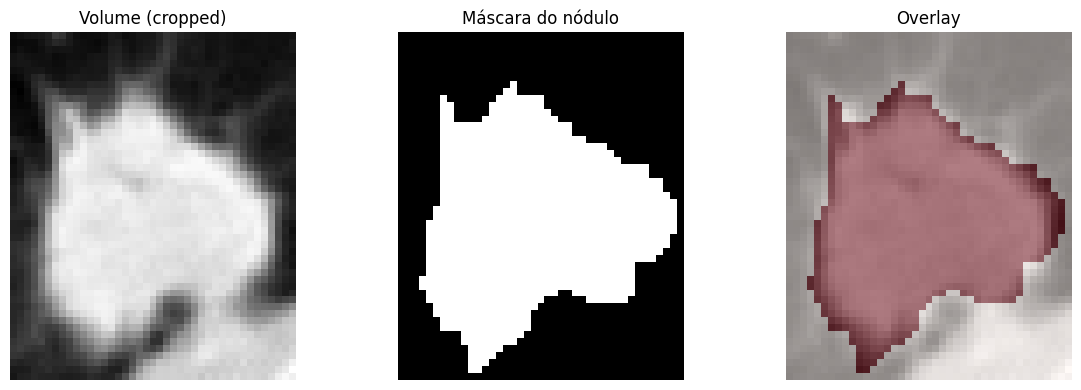

Diâmetro: 32.21 mm
Malignidade: 5
Textura: 5


In [27]:
scan = pl.query(pl.Scan).filter(pl.Scan.patient_id == 'LIDC-IDRI-0001').first()
clusters = scan.cluster_annotations()

if len(clusters) > 0:
    cluster = clusters[0]
    ann = cluster[0]  # primeira anotação do primeiro nódulo

    # Bounding box e máscara
    bbox = ann.bbox()
    volume = scan.to_volume()
    cropped = volume[bbox]
    mask = ann.boolean_mask()

    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    slice_idx = cropped.shape[2] // 2

    axes[0].imshow(cropped[:, :, slice_idx], cmap='gray')
    axes[0].set_title('Volume (cropped)')
    axes[0].axis('off')

    axes[1].imshow(mask[:, :, slice_idx], cmap='gray')
    axes[1].set_title('Máscara do nódulo')
    axes[1].axis('off')

    axes[2].imshow(cropped[:, :, slice_idx], cmap='gray')
    axes[2].imshow(mask[:, :, slice_idx], cmap='Reds', alpha=0.5)
    axes[2].set_title('Overlay')
    axes[2].axis('off')

    plt.tight_layout()
    plt.show()

    print(f"Diâmetro: {ann.diameter:.2f} mm")
    print(f"Malignidade: {ann.malignancy}")
    print(f"Textura: {ann.texture}")

Failed to reduce all groups to <= 4 Annotations.
Some nodules may be close and must be grouped manually.
Failed to reduce all groups to <= 4 Annotations.
Some nodules may be close and must be grouped manually.
Failed to reduce all groups to <= 4 Annotations.
Some nodules may be close and must be grouped manually.
Failed to reduce all groups to <= 4 Annotations.
Some nodules may be close and must be grouped manually.
Failed to reduce all groups to <= 4 Annotations.
Some nodules may be close and must be grouped manually.
Failed to reduce all groups to <= 4 Annotations.
Some nodules may be close and must be grouped manually.
Failed to reduce all groups to <= 4 Annotations.
Some nodules may be close and must be grouped manually.
Failed to reduce all groups to <= 4 Annotations.
Some nodules may be close and must be grouped manually.
Failed to reduce all groups to <= 4 Annotations.
Some nodules may be close and must be grouped manually.
Failed to reduce all groups to <= 4 Annotations.
Some n

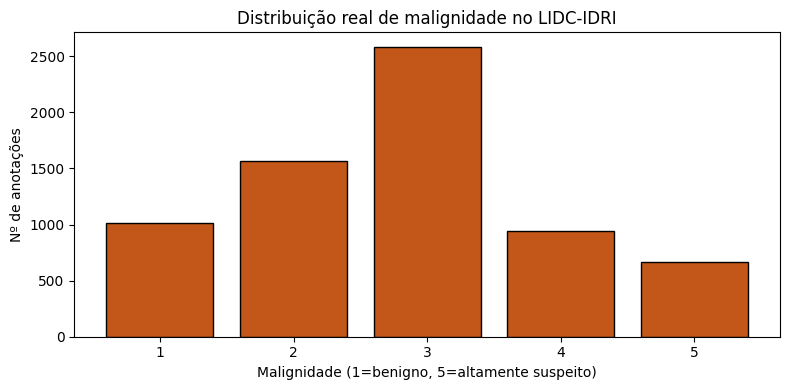

Total de anotações válidas: 6778

  malignidade=1:   1015 ( 15.0%)
  malignidade=2:   1570 ( 23.2%)
  malignidade=3:   2584 ( 38.1%)
  malignidade=4:    939 ( 13.9%)
  malignidade=5:    670 (  9.9%)


In [15]:
# Distribuição de malignidade em todo o dataset LIDC-IDRI- apenas como curiosidade
malignidades = []
for scan in pl.query(pl.Scan):
    for cluster in scan.cluster_annotations():
        if len(cluster) > 4:  # ignora clusters bugados
            continue
        for ann in cluster:
            if ann.malignancy is not None:
                malignidades.append(ann.malignancy)

import collections
dist = collections.Counter(malignidades)

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(dist.keys(), dist.values(), color='#c25719', edgecolor='black')
ax.set_xlabel('Malignidade (1=benigno, 5=altamente suspeito)')
ax.set_ylabel('Nº de anotações')
ax.set_title('Distribuição real de malignidade no LIDC-IDRI')
ax.set_xticks([1, 2, 3, 4, 5])
plt.tight_layout()
plt.show()

print("Total de anotações válidas:", sum(dist.values()))
print()
for k in sorted(dist):
    pct = 100 * dist[k] / sum(dist.values())
    print(f"  malignidade={k}: {dist[k]:6d} ({pct:5.1f}%)")

**Nota:** este histograma conta cada anotação individualmente.
Um nódulo com 4 radiólogos contribui com 4 contagens.

## 6. Análise de Malignidade

## Diferenças relevantes LIDC-IDRI vs. LNDb

### Diferenças estruturais

| Aspeto | LIDC-IDRI | LNDb |
|---|---|---|
| **Nº de scans** | 1018 séries de TC | 294 séries |
| **Nº de instituições** | 7 | 1 (CHUSJ, Porto) |
| **Metodologia** | 4 radiólogos, 2 fases (blinded + unblinded) | 5 radiólogos, single-blind |
| **Identidade dos radiologistas** | Anónima, não rastreável entre scans | Rastreável (R1-R5 consistentes) |
| **Formato das imagens** | DICOM (.dcm) por fatia | MetaImage (.mhd/.raw) |
| **Formato das anotações** | XML (`LidcReadMessage`) com contornos por fatia | CSV com coordenadas 3D do centro + volume |
| **Segmentação** | Contornos 2D por fatia (é preciso reconstruir) | Máscara 3D pré-computada |
| **Volume do nódulo** | Calculado a partir do contorno | Fornecido diretamente (em mm³) |
| **Diâmetro** | Calculado (`annotation.diameter`) | Calculado por `nodEqDiam` a partir do volume |
| **Características subjetivas** | 9 (subtlety, internalStructure, calcification, sphericity, margin, lobulation, spiculation, texture, malignancy) | 7 (calcification, internalStructure, lobulation, malignancy, margin, sphericity, spiculation, subtlety) |
| **Conjunto de treino** | Não há split oficial | Split oficial `train`/`test` |
| **Aquisição** | Muito heterogénea (7 instituições, vários scanners) | Homogénea (1 instituição) |

### Implicações para o pipeline


1. Distribuição de labels por radiologista, não por nódulo.</strong> Se um nódulo tem 4 anotações e 3 radiólogos lhe deram malignidade = 2 e 1 deu = 3, a linha "oficial" não existe — temos de decidir como agregar (média, mediana, maioria, ou manter as 4 linhas separadas como no LNDb).

2. **A máscara é 3D mas esparsa.** No LNDb a máscara é um volume binário denso. No LIDC, `ann.boolean_mask()` devolve uma máscara no bounding box — o pipeline tem de lidar com ambas.

3. **Contornos têm de ser fundidos.** Se quisermos uma máscara "de consenso" (como no LNDb, em que há uma máscara por nódulo), temos de aplicar `pl.utils.consensus()` ou uma regra de maioria.

4. **Não há `RadID` estável.** Não vai ser possível usar o radiologista como feature.

5. **Escalas diferentes.** No LNDb, os valores de `malignancy` vêm diretamente do CSV. No LIDC, `pylidc` normaliza.

6. Ficheiros XML duplicados.</strong> O pacote oficial contém, para cada série de TC, um XML de TC (<code>LidcReadMessage</code>) e frequentemente um XML de radiografia de tórax (<code>IdriReadMessage</code>). O <code>pylidc</code> <strong>só processa os XMLs de TC</strong>.


### Atenção

Para aceder ao volume é preciso ter as imagens DICOM em disco e configurar o `pylidcrc` com o caminho correto. No LNDb, o `utils.py` lê diretamente o `.mhd`. Além disso, ao contrário do LNDb (que fornece volumes pré-computados em MetaImage), o LIDC-IDRI guarda os contornos como sequências de pontos <code>(x, y, z)</code> por fatia. O volume tem de ser reconstruído.

Cada radiologista marcou as lesões em três categorias: <em>nódulo ≥ 3 mm</em>, <em>nódulo &lt; 3 mm</em>, e <em>não-nódulo ≥ 3 mm</em>. Apenas nódulos ≥ 3 mm têm contornos 3D e as 9 características subjetivas.